# Day 38 - Handling Imbalaced Dataset ( Fraudulent Detection )

Banyak masalah dunia nyata punya kelas yang **sangat tidak seimbang**: penipuan kartu kredit, penyakit langka, kerusakan mesin. Di notebook ini Saya belajar cara menangani data semacam itu menggunakan kasus klasik: **deteksi transaksi penipuan (fraud) kartu kredit**.

> 🎯 **Tujuan Pembelajaran**
> - Mengenali masalah **imbalanced data** dan kenapa **akurasi menyesatkan**.
> - Membuat **sampel** yang ringan dari data 284.000 baris.
> - Memakai `class_weight="balanced"` untuk membantu model fokus ke kelas minoritas.
> - Memahami **precision, recall, PR-AUC** (`average_precision_score`) dan kurva Precision-Recall.
> - Menggeser **ambang (threshold)** keputusan untuk menyeimbangkan precision vs recall.

## About Dataset

Dataset **Credit Card Fraud** berisi transaksi kartu kredit nasabah Eropa pada September 2013.
Demi privasi, sebagian besar fitur sudah dittransformasi PCA menjadi `V1`–`V28`.

- **Sumber:** [Kaggle — mlg-ulb/creditcardfraud](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud)
- **Jumlah data asli:** 284.807 baris × 31 kolom

| Kolom | Arti |
|-------|------|
| `Time` | Detik sejak transaksi pertama |
| `V1`–`V28` | Fitur hasil transformasi PCA (anonim) |
| `Amount` | Nominal transaksi |
| `Class` | **Target**: 0 = normal, 1 = fraud |

Karena hanya **0,17%** transaksi adalah fraud, ini contoh sempurna data tidak seimbang.

## Import Library

- **pandas / numpy** → olah data.
- **matplotlib / seaborn** → visualisasi.
- **sklearn** → `LogisticRegression`, metrik (`precision_recall_curve`,
  `average_precision_score`, `confusion_matrix`, `classification_report`).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_curve, average_precision_score, confusion_matrix, classification_report, precision_score, recall_score, f1_score, accuracy_score

## Import Dataset

In [3]:
!pip install kaggle
!mkdir ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d mlg-ulb/creditcardfraud
!unzip creditcardfraud.zip

cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud
License(s): DbCL-1.0
100% 66.0M/66.0M [00:00<00:00, 152MB/s]

Archive:  creditcardfraud.zip
  inflating: creditcard.csv          


In [4]:
df = pd.read_csv('creditcard.csv')
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [6]:
df.shape

(284807, 31)

**Interpretasi :**

- Data terdiri dari 284807 Baris dan 31 Kolom

## Early Exploration

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [8]:
df.isnull().sum().sum()

np.int64(0)

**Interpretasi :**
- Tidak ada missing value

## Create Sample


Data penuh terlalu besar untuk dieksekusi cepat. Strategi:

- **ambil SEMUA baris fraud** (`Class == 1`, sangat berharga) + **sampel acak ~8.000 baris normal** (`Class == 0`).
- Dengan `random_state=42` hasilnya selalu sama (reproducible).

Ini bukan data dummy — kita hanya mengambil sebagian baris nyata.

In [10]:
fraud = df[df['Class']==1]
normal = df[df['Class']==0].sample(n=8000, random_state=42)

df_sample = pd.concat([fraud, normal]).sample(frac=1, random_state=42).reset_index(drop=True)

print(f'Jumlah baris fraud: {len(fraud)}')
print(f'Jumlah baris normal: {len(normal)}')

Jumlah baris fraud: 492
Jumlah baris normal: 8000


**Interpretasi :**

- Sampel berisi seluruh transaksi fraud yang ada plus 8.000 transaksi
normal.
- Meski sudah disampel, kelas tetap **timpang** (fraud masih sangat minoritas), persis seperti kondisi nyata yang ingin dipelajari.

## Imbalanced Dataset

In [17]:
imb_data = df_sample['Class'].value_counts()
imb_data

,count
Class,
0,8000
1,492


In [18]:
print("\nProporsi fraud: {:.2%}".format(df_sample["Class"].mean()))


Proporsi fraud: 5.79%


/tmp/ipykernel_517/4134622421.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Class', data=df_sample, palette="Set2")


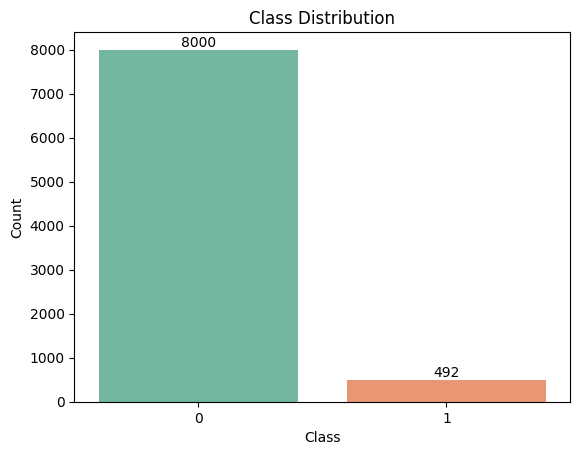

In [21]:
sns.countplot(x='Class', data=df_sample, palette="Set2")
plt.title('Class Distribution')
plt.xlabel('Class')
plt.ylabel('Count')
for i in range(len(imb_data)):
    plt.text(i, imb_data[i], str(imb_data[i]), ha='center', va='bottom')
plt.show()

**Interpretasi :**
- Kelas 0 (Transaksi Normal): 8.000 sampel   
- Kelas 1 (Transaksi Fraud/Penipuan): 492 sampel  

Interpretasi untuk Stakeholder / C-Level:
  - Perbaikan Proporsi yang Signifikan: Meskipun masih tidak seimbang (imbalanced), rasio ini jauh lebih sehat dibandingkan data aslinya yang tadinya hanya memiliki 0,17% data penipuan.
  - Jumlah data fraud kini terwakili dengan jauh lebih baik (492 kasus).
  
Keseimbangan Model:
  - Komposisi 8.000 berbanding 492 memberikan ruang yang cukup bagi algoritma Machine Learning untuk mengenali pola anomali penipuan tanpa membuat proses pelatihan menjadi terlalu timpang atau overfitting terhadap data normal.

## Exploratory Data Analysis and Visualization

Apakah nominal (`Amount`) berbeda antara transaksi normal dan fraud?

/tmp/ipykernel_517/585624598.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Class', y='Amount', data=df_sample, palette="Set2")


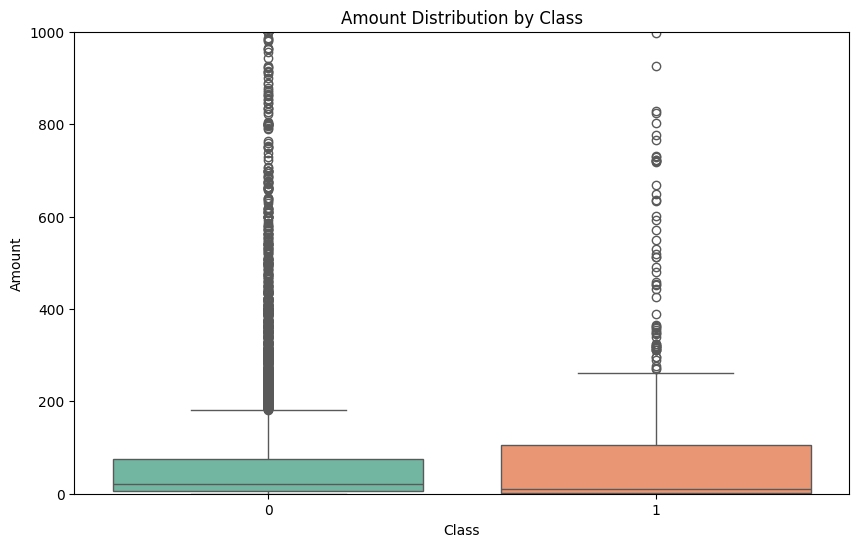

In [23]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='Class', y='Amount', data=df_sample, palette="Set2")
plt.title('Amount Distribution by Class')
plt.ylim(0, 1000)
plt.xlabel('Class')
plt.ylabel('Amount')
plt.show()

**Interpretasi :**

- Kelas 0 (Transaksi Normal/Sahih):
  - Sebagian besar transaksi normal bernilai kecil (terpusat di nominal rendah), namun memiliki sangat banyak titik pencilan (outliers) ke atas hingga nominal ribuan.
  - Ini menunjukkan bahwa transaksi sah memiliki variasi jumlah uang yang sangat luas, dari pembelian kecil hingga nominal besar.   

- Kelas 1 (Transaksi Fraud/Penipuan):
  - Distribusi nilai nominal pada transaksi penipuan juga cenderung berada di kisaran nominal yang relatif rendah pada bagian utamanya (median/kuartil bawah mendekati nilai kecil), tetapi tetap memiliki beberapa transaksi bernilai tinggi.   
  
Kesimpulan untuk Stakeholder / C-Level:
  - Nominal transaksi saja tidak bisa menjadi pembeda mutlak untuk mendeteksi penipuan. Baik transaksi normal maupun fraud sama-sama banyak terjadi pada nominal yang kecil. Oleh karena itu, sistem keamanan tidak boleh hanya berpatokan pada besar-kecilnya nilai uang (amount), melainkan harus digabungkan dengan pola perilaku lain (seperti lokasi, waktu, atau frekuensi) untuk mendeteksi fraud secara akurat.

## Preprocessing

Pisahkan fitur & target, lakukan split dengan `stratify` (agar proporsi fraud sama di latih & uji), lalu scaling. `Time` dan `Amount` punya skala berbeda dari V1–V28, jadi scaling menyamakannya

In [24]:
#Fitur & Label Splitting
X = df_sample.drop('Class', axis=1)
y = df_sample['Class']


In [25]:
#Train-Test-Splitting
X_train, X_test, y_train, y_test = train_test_split(X,
                                                    y,
                                                    test_size=0.2,
                                                    random_state=42, stratify=y)

In [26]:
#Standarisasi
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [30]:
#ChechResult

print(f'Jumlah baris data latih: {len(X_train)}')

print(f'Jumlah baris data uji: {len(X_test)}')


print(f'\nProporsi fraud data latih: {y_train.mean():.2%}')
print(f'Proporsi fraud data uji: {y_test.mean():.2%}')

Jumlah baris data latih: 6793
Jumlah baris data uji: 1699

Proporsi fraud data latih: 5.80%
Proporsi fraud data uji: 5.77%


**Interpretasi :**
- Data dibagi menjadi Fitur dan Label Y
- Setelah dibagi, pisahkan menjadi data latih dan data test
- Lakukan Standarisasi Data untuk data Latih
- Cek Proporsi Data masing masing Latih dan Test

## Modeling Baseline vs Class_Weight="Balanced"


Kita latih **dua** Logistic Regression:
1. **Baseline** (tanpa penyeimbangan) — mewakili model "naif".
2. **Balanced** (`class_weight="balanced"`) — memberi bobot lebih besar pada kelas fraud sehingga model "dipaksa" memperhatikan minoritas

In [32]:
base_model = LogisticRegression(max_iter=1000, random_state=42)
base_model.fit(X_train, y_train)
pred_base_model = base_model.predict(X_test)

balanced_model = LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced')
balanced_model.fit(X_train, y_train)
pred_balanced_model = balanced_model.predict(X_test)

In [34]:
print("== Baseline ==")
print(classification_report(y_test, pred_base_model))

print("== Balanced ==")
print(classification_report(y_test, pred_balanced_model))


== Baseline ==
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      1601
           1       0.97      0.86      0.91        98

    accuracy                           0.99      1699
   macro avg       0.98      0.93      0.95      1699
weighted avg       0.99      0.99      0.99      1699

== Balanced ==
              precision    recall  f1-score   support

           0       0.99      0.97      0.98      1601
           1       0.68      0.91      0.78        98

    accuracy                           0.97      1699
   macro avg       0.84      0.94      0.88      1699
weighted avg       0.98      0.97      0.97      1699



**Interpretasi :**

1. Model Baseline (Sebelum Penyeimbangan Data)
    - Akurasi Sangat Tinggi (99%): Secara keseluruhan terlihat sangat sempurna.

    - Kelebihan (Kelas 0 / Normal): Sangat handal mendeteksi transaksi normal dengan recall 1.00% (hampir tidak ada transaksi normal yang salah dideteksi).

    - Kekurangan (Kelas 1 / Fraud): Memiliki recall 0.86, artinya dari 98 kasus fraud yang terjadi, ada sekitar 14 kasus penipuan lolos (kecolongan) dari sistem.

2. Model Balanced (Sesudah Penyeimbangan Data/Undersampling)
    - Akurasi Tetap Tinggi (97%): Sedikit turun dari baseline, namun masih sangat baik untuk ukuran sistem deteksi anomali.

    - Kelebihan (Kelas 1 / Fraud): Recall meningkat drastis menjadi 0.91. Dari 98 kasus fraud, model kini berhasil mendeteksi lebih banyak (hanya menyisakan sekitar 8-9 kasus yang lolos).

    - Kekurangan (False Alarm / Presisi Turun): Presisi kelas 1 turun menjadi 0.68. Artinya, dari semua transaksi yang dicurigai fraud oleh model, ada sekitar 32% yang ternyata merupakan transaksi normal (false alarm yang mungkin memicu verifikasi ulang ke nasabah).

Kesimpulan & Perbandingan untuk C-Level:

   - Model Baseline lebih "tenang" dan sedikit menghasilkan false alarm, namun lemah dalam menangkap penipuan (banyak fraud yang lolos).

   - Model Balanced lebih "agresif dan waspada", sangat bagus untuk menekan angka kecolongan fraud (recall naik ke 91%), tetapi konsekuensinya adalah peningkatan jumlah false alarm (sedikit lebih sering salah menuduh transaksi sah sebagai penipuan).

Rekomendasi Bisnis:

  - Untuk kasus fraud, Model Balanced biasanya lebih dipilih karena kerugian akibat kecolongan penipuan jauh lebih mahal daripada repotnya verifikasi tambahan pada false alarm.

In [36]:
# Get dictionary classification reports for the trained Logistic Regression models
report_base = classification_report(y_test, pred_base_model, target_names=["Normal", "Fraud"], output_dict=True)
report_balanced = classification_report(y_test, pred_balanced_model, target_names=["Normal", "Fraud"], output_dict=True)

# Construct summary DataFrame comparing Baseline vs Balanced
result = pd.DataFrame({
    'Model': ['Baseline Logistic Regression', 'Balanced Logistic Regression'],
    'Akurasi': [
        accuracy_score(y_test, pred_base_model),
        accuracy_score(y_test, pred_balanced_model)
    ],
    'Presisi Normal': [
        report_base['Normal']['precision'],
        report_balanced['Normal']['precision']
    ],
    'Presisi Fraud': [
        report_base['Fraud']['precision'],
        report_balanced['Fraud']['precision']
    ],
    'Recall Normal': [
        report_base['Normal']['recall'],
        report_balanced['Normal']['recall']
    ],
    'Recall Fraud': [
        report_base['Fraud']['recall'],
        report_balanced['Fraud']['recall']
    ]
})

result

,Model,Akurasi,Presisi Normal,Presisi Fraud,Recall Normal,Recall Fraud
0,Baseline Logistic Regression,0.989994,0.991315,0.965517,0.998126,0.857143
1,Balanced Logistic Regression,0.970571,0.994264,0.684615,0.974391,0.908163


**Interpretasi :**
- Baseline Logistic Regression (Model Pertama):
  - Sangat Presisi pada Transaksi Normal: Memiliki tingkat ketepatan yang tinggi, namun lemah dalam menangkap fraud (Recall Fraud hanya 0.857 atau 85,7%). Artinya, masih ada cukup banyak kasus penipuan yang lolos dari sistem.

- Balanced Logistic Regression (Model Kedua):
  - Lebih Agresif Menangkap Fraud: Berhasil menaikkan tangkapan penipuan menjadi 0.908 (90,8%).
  - Konsekuensinya, Presisi untuk kelas fraud turun menjadi 0.684, yang berarti akan lebih sering terjadi false alarm (transaksi normal yang keliru dicurigai sebagai penipuan).

Kesimpulan untuk C-Level:
- Pola perbandingannya tetap sama: Model Baseline lebih aman dari false alarm tapi banyak meloloskan fraud, sedangkan Model Balanced jauh lebih optimal untuk keamanan karena lebih sedikit kebobolan kasus penipuan.

## Model Evaluation (Balanced Model)

###Confusion Metrix & Classification Report

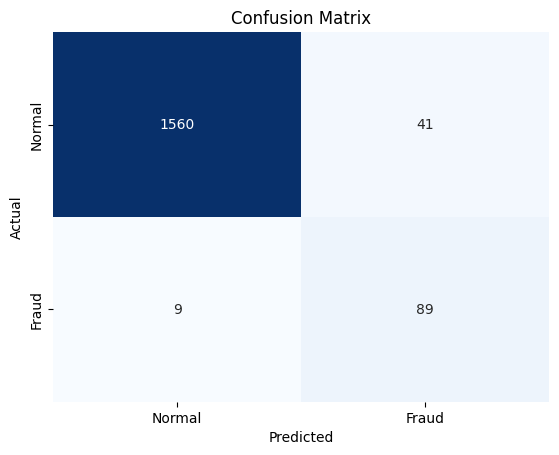

In [37]:
conf_mat = confusion_matrix(y_test, pred_balanced_model)
sns.heatmap(conf_mat, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Normal', 'Fraud'], yticklabels=['Normal', 'Fraud'])

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

**Interpretasi**

Prediksi Benar (Diagonal):
  - 1.560 transaksi (Normal ke Normal): Transaksi sah yang berhasil dikenali dengan sangat akurat oleh model.   
  - 89 transaksi (Fraud ke Fraud): Kasus penipuan (fraud) yang berhasil dideteksi dengan benar oleh model.
  - Angka ini mencerminkan performa recall kelas minoritas yang tinggi (sekitar 91%, sesuai dengan pembahasan Balanced Model sebelumnya).   

Prediksi Salah (Keliru):
  - 41 transaksi (Normal ke Fraud / False Positive): Transaksi sah yang keliru dicurigai sebagai penipuan (false alarm). Ini adalah "biaya operasional" yang harus dibayar berupa sedikit kerepotan verifikasi ulang bagi nasabah.   
  - 9 transaksi (Fraud ke Normal / False Negative): Kasus penipuan yang lolos dari deteksi dan dianggap sebagai transaksi normal oleh model. Jumlahnya sudah berhasil ditekan seminimal mungkin.   
  
Kesimpulan untuk Stakeholder / C-Level:
  - Model ini sudah bekerja dengan sangat baik dan selaras dengan strategi bisnis . Dari total kasus penipuan yang ada, model berhasil mengamankan sebagian besar (89 kasus) dan hanya meloloskan 9 kasus saja.
  - Meskipun ada 41 transaksi normal yang ikut terdeteksi sebagai peringatan palsu (false alarm), pengorbanan ini jauh lebih baik ketimbang harus kecolongan kerugian finansial yang masif dari kasus fraud yang lolos

### Curve Precision-Recall & PR Area Under the Curve

Untuk data tidak seimbang,

- **kurva Precision-Recall** lebih informatif daripada ROC.
- **PR-AUC** (`average_precision_score`) merangkum kurva ini jadi satu angka (semakin tinggi
semakin baik).

Kita pakai `predict_proba` untuk mendapatkan probabilitas fraud.

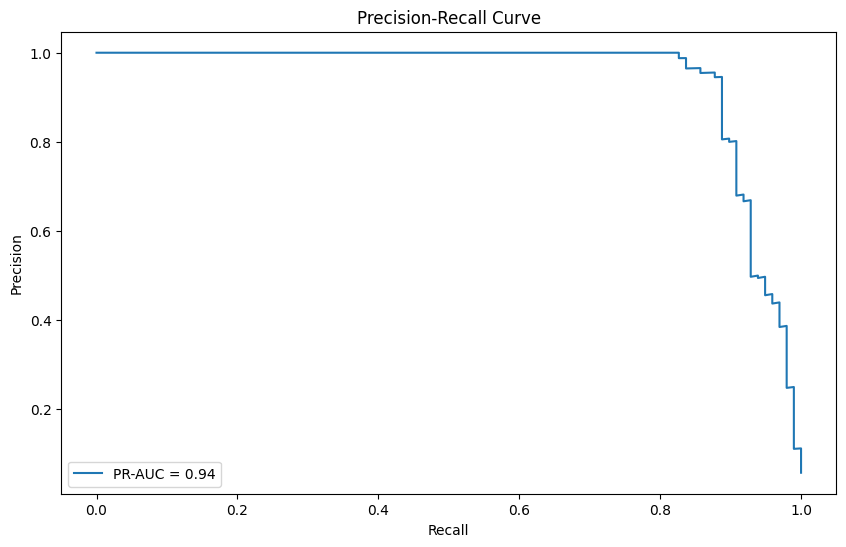

In [39]:
prob = balanced_model.predict_proba(X_test)[:, 1]
precision, recall, threshold = precision_recall_curve(y_test, prob)
pr_auc = average_precision_score(y_test, prob)

plt.figure(figsize=(10, 6))
plt.plot(recall, precision, label=f'PR-AUC = {pr_auc:.2f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.show()

**Interpretasi :**

- Nilai PR-AUC = 0.94:
  - Metrik rangkuman performa model menunjukkan angka 0,94. Karena nilai maksimum yang sempurna adalah 1.0, angka ini membuktikan bahwa kualitas model dalam mendeteksi kelas minoritas (fraud) berada pada tingkat yang sangat tinggi dan sangat handal.   

- Kestabilan Performa (Trade-off):
  - Garis grafik terlihat bertahan di level atas yang sangat tinggi (mendekati presisi 1.0) dari titik recall 0 hingga sekitar 0,8.
  - Artinya, model mampu menangkap sebagian besar kasus penipuan dengan ketepatan yang luar biasa, sebelum akhirnya presisi mulai menurun secara bertahap saat model dipaksa mendeteksi hingga mendekati 100% recall.   

Kesimpulan untuk C-Level:
  - Grafik ini mengonfirmasi bahwa sistem deteksi penipuan memiliki performa prediktif yang sangat kuat dan stabil.
  - Model mampu menyeimbangkan tangkapan kasus fraud secara maksimal tanpa menghasilkan lonjakan false alarm yang berlebihan, sehingga sangat layak untuk diandalkan dalam operasional bisnis sehari-hari.   

## Adjust the Threshould

Secara default, model menandai fraud bila probabilitas > 0,5.

Tapi kita bisa **menurunkan ambang** untuk menangkap lebih banyak fraud (recall naik) dengan risiko lebih banyak alarm palsu (precision turun). Mari bandingkan beberapa threshold.

In [41]:
for t in [0.3, 0.5, 0.7]:
  pred_t = (prob >= t).astype(int)
  p = precision_score(y_test, pred_t)
  r = recall_score(y_test, pred_t)
  print(f"Threshold {t}: precision={p:.3f}  recall={r:.3f}  "
          f"fraud tertangkap={int(((pred_t==1)&(y_test==1)).sum())}/{int(y_test.sum())}")

Threshold 0.3: precision=0.497  recall=0.949  fraud tertangkap=93/98
Threshold 0.5: precision=0.685  recall=0.908  fraud tertangkap=89/98
Threshold 0.7: precision=0.807  recall=0.898  fraud tertangkap=88/98


Analisis Perbandingan Threshold (Ambang Batas Model Fraud)
  - Threshold 0.3 (Sangat Agresif / Mode Keamanan Maksimal):
    - Kelebihan: Menangkap jumlah fraud paling banyak (93 dari 98 kasus tertangkap / recall tertinggi di 94.9%). Sangat sedikit kasus penipuan yang lolos.   
    - Kekurangan: Precision turun drastis ke 49.7%. Artinya, dari setiap dua peringatan penipuan yang dibunyikan sistem, hampir separuhnya ternyata adalah false alarm (transaksi normal yang ikut terciduk), sehingga tim operasional harus bekerja ekstra untuk verifikasi manual.

  - Threshold 0.5 (Titik Keseimbangan / Default):
    - Kelebihan: Memberikan titik tengah yang ideal antara keamanan dan kenyamanan. Model berhasil menangkap 89 dari 98 kasus penipuan (recall 90.8%).   
    - Kekurangan: Precision meningkat cukup baik ke 68.5%, sehingga jumlah false alarm jauh berkurang dibanding threshold 0.3, namun masih ada 9 kasus penipuan yang lolos.

  - Threshold 0.7 (Konservatif / Mengurangi False Alarm):
    - Kelebihan: Precision sangat tinggi (80.7%), yang berarti peringatan yang diberikan sistem jauh lebih akurat dan sedikit sekali false alarm.
    - Kekurangan: Jumlah fraud yang tertangkap mulai menurun (88 dari 98 kasus), artinya tingkat kecolongan (false negative) mulai bertambah.   
    
Kesimpulan & Rekomendasi Bisnis untuk C-Level:
  - Pemilihan threshold bergantung pada toleransi risiko perusahaan:Jika fokus utama adalah menutup celah kerugian sebesar-besarnya, Threshold 0.3 adalah pilihan terbaik karena paling sedikit meloloskan fraud (93/98), meski harus dibayar dengan lebih banyak kerjaan verifikasi false alarm.   
  - Jika ingin mencari titik kompromi terbaik antara efisiensi operasional dan keamanan, Threshold 0.5 memberikan hasil yang sangat stabil dan optimal secara bisnis.

## Resampling (SMOTE)

Selain `class_weight` dan menggeser threshold, pendekatan populer lain adalah **mengubah komposisi data latih**:

- **Undersampling** — buang sebagian data kelas mayoritas (seperti yang kita lakukan saat sampling di awal).
- **Oversampling / SMOTE** — perbanyak kelas minoritas. **SMOTE** (*Synthetic Minority Over-sampling   Technique*) membuat contoh fraud **sintetis** dengan menginterpolasi antar tetangga terdekat, bukan sekadar menggandakan baris.

⚠️ **Penting:** resampling hanya boleh diterapkan pada **data latih**, *setelah* split — jangan pernah meng-oversample seluruh data lalu baru split (data uji jadi "bocor" & skor palsu). SMOTE tersedia di pustaka `imbalanced-learn` (`imblearn`); kita tidak memakainya di sini agar dependensi tetap ringan, tetapi `class_weight` sudah memberi manfaat serupa tanpa menambah data.

### 🎯 Kesimpulan Utama & Rekomendasi Bisnis

Berdasarkan rangkaian eksperimen penanganan *imbalanced data* pada transaksi kartu kredit ini, berikut adalah beberapa poin penting yang dapat diajukan kepada jajaran manajemen atau stakeholder:

#### 1. Bahaya Menggunakan Akurasi sebagai Metrik Tunggal
* **Model Baseline** mencatatkan akurasi luar biasa sebesar **99.00%**. Namun, model ini meloloskan **14 dari 98 kasus penipuan** (Recall Fraud hanya ~85.7%).
* Dalam skenario dunia nyata, meloloskan penipuan jauh lebih mahal secara finansial dan reputasi dibanding sekadar melacak transaksi yang dicurigai.

#### 2. Keunggulan Model Seimbang (`class_weight='balanced'`)
* Dengan mengaktifkan penyeimbangan bobot kelas, **Recall meningkat secara signifikan menjadi 90.8%** (hanya 9 kasus penipuan yang lolos dari total 98 kasus).
* Konsekuensi yang harus diterima adalah penurunan presisi menjadi **68.5%**, yang berarti munculnya **41 kasus alarm palsu** (*false positive*) dari total 1.601 transaksi normal.

#### 3. Optimasi Operasional via Penyesuaian Threshold (Ambang Batas)
Keputusan operasional dapat disesuaikan secara fleksibel bergantung pada tingkat toleransi risiko perusahaan:
* **Threshold 0.3 (Mode Proteksi Maksimal):** Direkomendasikan jika tujuan utama adalah menekan kerugian finansial akibat kebocoran transaksi fraud sekecil mungkin. Menangkap **93 dari 98 kasus fraud** (Recall ~94.9%), namun tim operasional harus siap menangani lebih banyak panggilan verifikasi (*false alarm* ~50%).
* **Threshold 0.5 (Mode Kompromi Bisnis):** Pilihan paling stabil untuk menjaga kepuasan nasabah sekaligus mendeteksi mayoritas fraud secara seimbang.
* **Threshold 0.7 (Mode Efisiensi Operasional):** Dipilih jika sumber daya tim investigasi sangat terbatas, untuk meminimalkan alarm palsu (Presisi naik ke ~80.7%).

---